In [4]:
%load_ext autoreload
%autoreload 2  
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent)) 
from sst2 import *

train, validation, test = load_sst2()
tokenizer = get_tokenizer(train)
cv_sets = get_cv_splits(train)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import json
from pathlib import Path

import torch
import torch.nn as nn
import part1.smlp
from part1.experiment import cross_validation_experiment

activation_results = {}
BaseSparseMLP = part1.smlp.SparseMLP

def make_activation_model(activation_class):
    class ActivationSparseMLP(BaseSparseMLP):
        def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
            super().__init__(input_dim, hidden_dim, num_classes, dropout)
            self.activation = activation_class()
    return ActivationSparseMLP

try:
    for variant, activation_class in {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}.items():
        part1.smlp.SparseMLP = make_activation_model(activation_class)
        accuracies = []

        for fold, split in cv_sets[0].items():
            torch.manual_seed(fold)  # same starting weights for all three models
            fold_result = cross_validation_experiment(
                data_splits={fold: split},
                outcome_space=CLASSES,
                encoder=BagOfWords(tokenizer),
                model_option="mlp",
                save_to=f"result1/bow-{variant}/seed-0",
            )
            accuracies.append(float(fold_result["accuracies"][fold]))

        activation_results[variant] = accuracies
finally:
    part1.smlp.SparseMLP = BaseSparseMLP  # back to the original model

Path("result1").mkdir(exist_ok=True)
with open("result1/activation_results.json", "w") as f:
    json.dump(activation_results, f, indent=2)


  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 19.834 seconds
Dataloader done! Time taken: 1.856 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3808 | train acc: 0.8276 | val loss: 0.2764 | val acc: 0.8873
Epoch 02 | train loss: 0.2225 | train acc: 0.9115 | val loss: 0.2364 | val acc: 0.9102
Epoch 03 | train loss: 0.1616 | train acc: 0.9391 | val loss: 0.2171 | val acc: 0.9195


In [ ]:


ENCODERS = {
    "indicator": TokenIndicator,
    "bow": BagOfWords,
    "tfidf": TFIDFunigram,
}


In [39]:
from part1.experiment import cross_validation_experiment
results = {}
for encoder_name, encoder_class in ENCODERS.items():
    accuracies = []
    for fold, split in cv_sets[0].items():
        encoder = encoder_class(tokenizer)
        if encoder_name == "tfidf":
            encoder.fit([text for text, _ in split["training"]])

        fold_result = cross_validation_experiment(
            data_splits={fold: split},
            outcome_space=CLASSES,
            encoder=encoder,
            model_option="logistic",
                save_to=f"results/{encoder_name}-logistic/seed-0",
            loglin_args={"max_iter": 1000},
        )
        accuracies.append(fold_result["accuracies"][fold])
    results[(encoder_name, "logistic")] = accuracies

for (encoder_name, model_name), scores in results.items():
    print(f"{encoder_name:10s} {model_name:10s} mean={np.mean(scores):.4f} std={np.std(scores):.4f}")



  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

indicator  logistic   mean=0.8774 std=0.0028
bow        logistic   mean=0.8777 std=0.0027
tfidf      logistic   mean=0.8706 std=0.0028


In [41]:
from part1.experiment import cross_validation_experiment

for encoder_name, encoder_class in ENCODERS.items():
    accuracies = []
    for fold, split in cv_sets[0].items():
        encoder = encoder_class(tokenizer)
        if encoder_name == "tfidf":
            encoder.fit([text for text, _ in split["training"]])

        fold_result = cross_validation_experiment(
            data_splits={fold: split},
            outcome_space=CLASSES,
            encoder=encoder,
            model_option="mlp",
            save_to=f"results/{encoder_name}-smlp/seed-0",
            loglin_args={"max_iter": 1000},
        )
        accuracies.append(fold_result["accuracies"][fold])
    results[(encoder_name, "smlp")] = accuracies

for (encoder_name, model_name), scores in results.items():
    print(f"{encoder_name:10s} {model_name:10s} mean={np.mean(scores):.4f} std={np.std(scores):.4f}")



  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 19.669 seconds
Dataloader done! Time taken: 2.612 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3803 | train acc: 0.8301 | val loss: 0.2748 | val acc: 0.8847
Epoch 02 | train loss: 0.2238 | train acc: 0.9101 | val loss: 0.2341 | val acc: 0.9091
Epoch 03 | train loss: 0.1599 | train acc: 0.9401 | val loss: 0.2205 | val acc: 0.9170
Epoch 04 | train loss: 0.1191 | train acc: 0.9559 | val loss: 0.2211 | val acc: 0.9215
Epoch 05 | train loss: 0.0909 | train acc: 0.9681 | val loss: 0.2257 | val acc: 0.9266
Epoch 06 | train loss: 0.0732 | train acc: 0.9743 | val loss: 0.2444 | val acc: 0.9247
Epoch 07 | train loss: 0.0587 | train acc: 0.9801 | val loss: 0.2557 | val acc: 0.9258
Epoch 08 | train loss: 0.0500 | train acc: 0.9838 | val loss: 0.2685 | val acc: 0.9261
Epoch 09 | train loss: 0.0428 | train acc: 0.9862 | val loss: 0.2749 | val acc: 0.9284
Epoch 10 | train loss: 0.0376 | train acc: 0.9883 | val loss: 0.2933 | val acc: 0.9278
Epoch 11 | train loss: 0.0352 | train acc: 0.9886 | val loss: 0.3041 | val acc: 0.9285
Epoch 12 | train loss: 0.0328 | train acc: 

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 19.835 seconds
Dataloader done! Time taken: 2.809 seconds
Training...


... (50 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 2.787 seconds
Dataloader done! Time taken: 2.252 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3868 | train acc: 0.8175 | val loss: 0.2969 | val acc: 0.8741
Epoch 02 | train loss: 0.2577 | train acc: 0.8945 | val loss: 0.2728 | val acc: 0.8886
Epoch 03 | train loss: 0.2136 | train acc: 0.9140 | val loss: 0.2573 | val acc: 0.9006
Epoch 04 | train loss: 0.1727 | train acc: 0.9340 | val loss: 0.2522 | val acc: 0.9088
Epoch 05 | train loss: 0.1350 | train acc: 0.9509 | val loss: 0.2477 | val acc: 0.9154
Epoch 06 | train loss: 0.1028 | train acc: 0.9644 | val loss: 0.2534 | val acc: 0.9169
Epoch 07 | train loss: 0.0792 | train acc: 0.9729 | val loss: 0.2667 | val acc: 0.9191
Epoch 08 | train loss: 0.0627 | train acc: 0.9787 | val loss: 0.2768 | val acc: 0.9213
Epoch 09 | train loss: 0.0500 | train acc: 0.9823 | val loss: 0.2921 | val acc: 0.9208
Epoch 10 | train loss: 0.0432 | train acc: 0.9851 | val loss: 0.3082 | val acc: 0.9221
Epoch 11 | train loss: 0.0370 | train acc: 0.9869 | val loss: 0.3209 | val acc: 0.9230
Epoch 12 | train loss: 0.0333 | train acc: 

In [8]:
import torch.nn as nn
import part1.smlp
from part1.experiment import cross_validation_experiment

results ={}
BaseSparseMLP = part1.smlp.SparseMLP

def make_kaiming_model(mode):
    class KaimingSparseMLP(BaseSparseMLP):
        def __init__(self, input_dim, hidden_dim, num_classes, dropout=0.2):
            super().__init__(input_dim, hidden_dim, num_classes, dropout)
            nn.init.kaiming_uniform_(self.weight, mode=mode, nonlinearity="relu")
    return KaimingSparseMLP

for variant, mode in {"kaiming-fan_out": "fan_out", "kaiming-fan_in": "fan_in"}.items():
    part1.smlp.SparseMLP = make_kaiming_model(mode)
    accuracies = []

    for fold, split in cv_sets[0].items():
        fold_result = cross_validation_experiment(
            data_splits={fold: split},
            outcome_space=CLASSES,
            encoder=BagOfWords(tokenizer),
            model_option="mlp",
            save_to=f"results/bow-{variant}/seed-0",
        )
        accuracies.append(fold_result["accuracies"][fold])

    results[("bow", variant)] = accuracies

part1.smlp.SparseMLP = BaseSparseMLP  # back to the original model




  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 18.781 seconds
Dataloader done! Time taken: 2.136 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.3793 | train acc: 0.8274 | val loss: 0.2718 | val acc: 0.8889
Epoch 02 | train loss: 0.2213 | train acc: 0.9127 | val loss: 0.2345 | val acc: 0.9094
Epoch 03 | train loss: 0.1597 | train acc: 0.9396 | val loss: 0.2225 | val acc: 0.9160
Epoch 04 | train loss: 0.1211 | train acc: 0.9553 | val loss: 0.2251 | val acc: 0.9209
Epoch 05 | train loss: 0.0935 | train acc: 0.9663 | val loss: 0.2323 | val acc: 0.9241
Epoch 06 | train loss: 0.0742 | train acc: 0.9742 | val loss: 0.2367 | val acc: 0.9281
Epoch 07 | train loss: 0.0614 | train acc: 0.9792 | val loss: 0.2509 | val acc: 0.9264
Epoch 08 | train loss: 0.0526 | train acc: 0.9828 | val loss: 0.2616 | val acc: 0.9270
Epoch 09 | train loss: 0.0462 | train acc: 0.9852 | val loss: 0.2725 | val acc: 0.9287
Epoch 10 | train loss: 0.0397 | train acc: 0.9871 | val loss: 0.2807 | val acc: 0.9286
Epoch 11 | train loss: 0.0346 | train acc: 0.9882 | val loss: 0.3002 | val acc: 0.9285
Epoch 12 | train loss: 0.0326 | train acc: 

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 18.817 seconds
Dataloader done! Time taken: 1.966 seconds
Training...


... (30 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 18.929 seconds
Dataloader done! Time taken: 2.061 seconds
Training...


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4237 | train acc: 0.8066 | val loss: 0.2903 | val acc: 0.8823
Epoch 02 | train loss: 0.2236 | train acc: 0.9140 | val loss: 0.2432 | val acc: 0.9097
Epoch 03 | train loss: 0.1591 | train acc: 0.9410 | val loss: 0.2342 | val acc: 0.9160
Epoch 04 | train loss: 0.1188 | train acc: 0.9575 | val loss: 0.2354 | val acc: 0.9186
Epoch 05 | train loss: 0.0927 | train acc: 0.9675 | val loss: 0.2523 | val acc: 0.9207
Epoch 06 | train loss: 0.0740 | train acc: 0.9749 | val loss: 0.2578 | val acc: 0.9204
Epoch 07 | train loss: 0.0631 | train acc: 0.9797 | val loss: 0.2683 | val acc: 0.9214
Epoch 08 | train loss: 0.0543 | train acc: 0.9832 | val loss: 0.2839 | val acc: 0.9235
Epoch 09 | train loss: 0.0464 | train acc: 0.9856 | val loss: 0.3007 | val acc: 0.9216
Epoch 10 | train loss: 0.0417 | train acc: 0.9877 | val loss: 0.3109 | val acc: 0.9217
Epoch 11 | train loss: 0.0379 | train acc: 0.9889 | val loss: 0.3142 | val acc: 0.9218
Epoch 12 | train loss: 0.0354 | train acc: 

Mean difference (Kaiming - Xavier): 0.0026
P(Xavier better):  3.2%
P(practically equal): 73.2%
P(Kaiming better): 23.6%


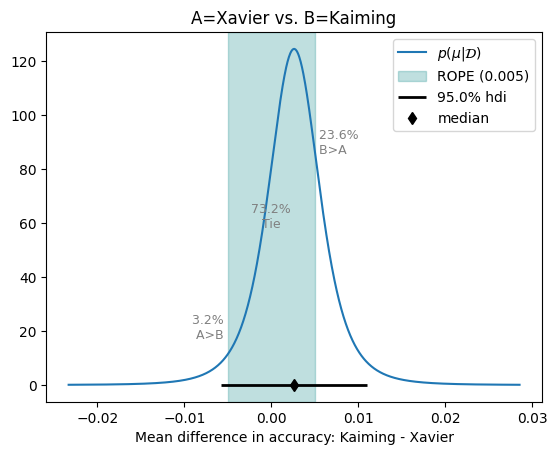

In [10]:
import matplotlib.pyplot as plt
from part1.analysis import BenavoliCorrelatedT

rope = 0.005
a = results[("bow", "kaiming-fan_in")]             # Xavier
b = results[("bow", "kaiming-fan_out")]  # Kaiming

assert len(a) == len(b) == 5, f"Expected 5 folds each, got {len(a)} and {len(b)}"

posterior = BenavoliCorrelatedT(a, b, runs=1, names=["Xavier", "Kaiming"])
p_a, p_tie, p_b = posterior.probs(rope)

print(f"Mean difference (Kaiming - Xavier): {posterior.mean_diff:.4f}")
print(f"P(Xavier better):  {p_a:.1%}")
print(f"P(practically equal): {p_tie:.1%}")
print(f"P(Kaiming better): {p_b:.1%}")

fig, ax = posterior.plot(rope_param=rope)
ax.set_xlabel("Mean difference in accuracy: Kaiming - Xavier")
plt.show()
